# Data Science Mini Project

Student Name: **Karthikeyan P**   
Batch: **DSB04**  
Project Title: **Electric Vehicle Population Analysis and EV Type Classification**  
Submission Date:
---

# 1. Problem Definition

## 1.1 Business / Real-World Problem Statement

Electric vehicles (EVs) include Battery Electric Vehicles (BEVs) and Plug-in Hybrid Electric Vehicles (PHEVs). Understanding the population of these vehicle types can help analysts explore the distribution of EVs by manufacturer, model year, and location. This project analyzes the supplied EV Vehicle Population dataset and builds a machine learning classifier to predict the recorded EV type from selected vehicle attributes.

**Scope note:** This dataset contains vehicle population records, not a complete measure of EV sales, charging activity, or future demand. Results describe this dataset only.

## 1.2 Project Objectives

- Understand the dataset structure and data quality.
- Clean missing values and inspect duplicate records.
- Perform exploratory data analysis (EDA) using summary statistics and visualizations.
- Compare EV types, manufacturers, model years, and electric range.
- Prepare features and train multiple classification models.
- Compare models using accuracy, precision, recall, F1-score, and confusion matrices.
- Explain limitations and possible future improvements.

## 1.3 Machine Learning Problem Type

**Supervised Learning – Classification**

**Target variable: Electric Vehicle Type**

**Prediction goal: Classifying a record as Battery Electric Vehicle (BEV) or Plug-in Hybrid Electric Vehicle (PHEV).**

# 2. Dataset Understanding

## 2.1 Dataset Source

**Dataset file supplied for this project:** https://raw.githubusercontent.com/karthi-95Entri/EV-Dataset/refs/heads/main/EV%20Vehicle%20Population%20data.csv  
**Source URL:** https://catalog.data.gov/dataset/electric-vehicle-population-data?from_hint=eyJzb3J0IjoicG9wdWxhcml0eSJ9

## 2.2 Dataset Description

The initial file has **256,902 rows and 11 columns**.

## 2.3 Feature Description

| Feature | Type | Description |
|---|---|---|
| County | Categorical | County recorded for the vehicle |
| City | Categorical | City recorded for the vehicle |
| State | Categorical | State abbreviation |
| Postal Code | Numeric / identifier | Postal code for the recorded location |
| Model Year | Numeric | Vehicle model year |
| Make | Categorical | Vehicle manufacturer |
| Model | Categorical | Vehicle model |
| Electric Vehicle Type | Categorical target | Recorded EV category (BEV or PHEV) |
| Electric Range | Numeric | Electric range value recorded in the dataset |
| Legislative District | Numeric / identifier | Legislative district value |
| DOL Vehicle ID | Identifier | Record-level vehicle identifier; excluded from model features |

## 2.4 Target Variable

- **Name: Electric Vehicle Type**
- **Description: Recorded category of the electric vehicle.**
- **Prediction goal: Predict BEV or PHEV from selected attributes.**

# 3. Exploratory Data Analysis (EDA)

## 3.1 Import Required Libraries

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 3.2 Load Dataset

In Google Colab, upload the CSV when prompted. If the CSV is already in the current working directory, the notebook loads it directly.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("https://raw.githubusercontent.com/karthi-95Entri/EV-Dataset/refs/heads/main/EV%20Vehicle%20Population%20data.csv")

print("Dataset shape:", df.shape)
display(df.head())
df.info()

Dataset shape: (256902, 11)


,County,City,State,Postal Code,Model Year,Make,Model,Electric Vehicle Type,Electric Range,Legislative District,DOL Vehicle ID
0,King,Seattle,WA,98177.0,2023,FORD,MUSTANG MACH-E,Battery Electric Vehicle (BEV),0.0,32.0,254622924
1,Thurston,Yelm,WA,98597.0,2025,MAZDA,CX-90,Plug-in Hybrid Electric Vehicle (PHEV),26.0,2.0,277791643
2,King,Sammamish,WA,98075.0,2018,TESLA,MODEL 3,Battery Electric Vehicle (BEV),215.0,41.0,347418676
3,Island,Oak Harbor,WA,98277.0,2019,HONDA,CLARITY,Plug-in Hybrid Electric Vehicle (PHEV),47.0,10.0,223620701
4,Kitsap,Bremerton,WA,98312.0,2024,JEEP,WRANGLER,Plug-in Hybrid Electric Vehicle (PHEV),21.0,26.0,256402674


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 256902 entries, 0 to 256901
Data columns (total 11 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   County                 256887 non-null  object 
 1   City                   256887 non-null  object 
 2   State                  256902 non-null  object 
 3   Postal Code            256887 non-null  float64
 4   Model Year             256902 non-null  int64  
 5   Make                   256902 non-null  object 
 6   Model                  256902 non-null  object 
 7   Electric Vehicle Type  256902 non-null  object 
 8   Electric Range         256871 non-null  float64
 9   Legislative District   256491 non-null  float64
 10  DOL Vehicle ID         256902 non-null  int64  
dtypes: float64(3), int64(2), object(6)
memory usage: 21.6+ MB


In [ ]:

df = df[df["State"] == "WA"]

print("Washington EV Dataset Shape:", df.shape)
display(df.head())

Washington EV Dataset Shape: (256492, 11)


,County,City,State,Postal Code,Model Year,Make,Model,Electric Vehicle Type,Electric Range,Legislative District,DOL Vehicle ID
0,King,Seattle,WA,98177.0,2023,FORD,MUSTANG MACH-E,Battery Electric Vehicle (BEV),0.0,32.0,254622924
1,Thurston,Yelm,WA,98597.0,2025,MAZDA,CX-90,Plug-in Hybrid Electric Vehicle (PHEV),26.0,2.0,277791643
2,King,Sammamish,WA,98075.0,2018,TESLA,MODEL 3,Battery Electric Vehicle (BEV),215.0,41.0,347418676
3,Island,Oak Harbor,WA,98277.0,2019,HONDA,CLARITY,Plug-in Hybrid Electric Vehicle (PHEV),47.0,10.0,223620701
4,Kitsap,Bremerton,WA,98312.0,2024,JEEP,WRANGLER,Plug-in Hybrid Electric Vehicle (PHEV),21.0,26.0,256402674


In [ ]:
df = df.drop(columns=["State"])

display(df.head())
print(df.shape)

,County,City,Postal Code,Model Year,Make,Model,Electric Vehicle Type,Electric Range,Legislative District,DOL Vehicle ID
0,King,Seattle,98177.0,2023,FORD,MUSTANG MACH-E,Battery Electric Vehicle (BEV),0.0,32.0,254622924
1,Thurston,Yelm,98597.0,2025,MAZDA,CX-90,Plug-in Hybrid Electric Vehicle (PHEV),26.0,2.0,277791643
2,King,Sammamish,98075.0,2018,TESLA,MODEL 3,Battery Electric Vehicle (BEV),215.0,41.0,347418676
3,Island,Oak Harbor,98277.0,2019,HONDA,CLARITY,Plug-in Hybrid Electric Vehicle (PHEV),47.0,10.0,223620701
4,Kitsap,Bremerton,98312.0,2024,JEEP,WRANGLER,Plug-in Hybrid Electric Vehicle (PHEV),21.0,26.0,256402674


(256492, 10)


In [ ]:

object_cols = df.select_dtypes(include="object").columns

print(object_cols)

for col in object_cols:
    print("\n", col)
    print(df[col].nunique())

Index(['County', 'City', 'Make', 'Model', 'Electric Vehicle Type'], dtype='object')

 County
39

 City
491

 Make
52

 Model
205

 Electric Vehicle Type
2


In [ ]:
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (256492, 10)


,County,City,Postal Code,Model Year,Make,Model,Electric Vehicle Type,Electric Range,Legislative District,DOL Vehicle ID
0,King,Seattle,98177.0,2023,FORD,MUSTANG MACH-E,Battery Electric Vehicle (BEV),0.0,32.0,254622924
1,Thurston,Yelm,98597.0,2025,MAZDA,CX-90,Plug-in Hybrid Electric Vehicle (PHEV),26.0,2.0,277791643
2,King,Sammamish,98075.0,2018,TESLA,MODEL 3,Battery Electric Vehicle (BEV),215.0,41.0,347418676
3,Island,Oak Harbor,98277.0,2019,HONDA,CLARITY,Plug-in Hybrid Electric Vehicle (PHEV),47.0,10.0,223620701
4,Kitsap,Bremerton,98312.0,2024,JEEP,WRANGLER,Plug-in Hybrid Electric Vehicle (PHEV),21.0,26.0,256402674


## 3.3 Dataset Overview

In [ ]:
display(df.head())
display(df.sample(min(5, len(df)), random_state=RANDOM_STATE))
print("\nShape:", df.shape)
print("\nData types:")
display(df.dtypes.rename("data_type").to_frame())
print("\nDescriptive statistics:")
display(df.describe(include="all").T)

,County,City,Postal Code,Model Year,Make,Model,Electric Vehicle Type,Electric Range,Legislative District,DOL Vehicle ID
0,King,Seattle,98177.0,2023,FORD,MUSTANG MACH-E,Battery Electric Vehicle (BEV),0.0,32.0,254622924
1,Thurston,Yelm,98597.0,2025,MAZDA,CX-90,Plug-in Hybrid Electric Vehicle (PHEV),26.0,2.0,277791643
2,King,Sammamish,98075.0,2018,TESLA,MODEL 3,Battery Electric Vehicle (BEV),215.0,41.0,347418676
3,Island,Oak Harbor,98277.0,2019,HONDA,CLARITY,Plug-in Hybrid Electric Vehicle (PHEV),47.0,10.0,223620701
4,Kitsap,Bremerton,98312.0,2024,JEEP,WRANGLER,Plug-in Hybrid Electric Vehicle (PHEV),21.0,26.0,256402674


,County,City,Postal Code,Model Year,Make,Model,Electric Vehicle Type,Electric Range,Legislative District,DOL Vehicle ID
180562,King,Kirkland,98033.0,2018,TESLA,MODEL 3,Battery Electric Vehicle (BEV),215.0,48.0,299812313
56074,Clark,Ridgefield,98642.0,2026,VOLKSWAGEN,ID.4,Battery Electric Vehicle (BEV),0.0,18.0,294920279
210035,King,Woodinville,98072.0,2017,TESLA,MODEL X,Battery Electric Vehicle (BEV),200.0,45.0,135133372
196420,Spokane,Spokane,99205.0,2025,JEEP,WAGONEER S,Battery Electric Vehicle (BEV),0.0,3.0,287419373
246359,Pierce,Tacoma,98407.0,2022,NISSAN,LEAF,Battery Electric Vehicle (BEV),0.0,27.0,187586003



Shape: (256492, 10)

Data types:


,data_type
County,object
City,object
Postal Code,float64
Model Year,int64
Make,object
Model,object
Electric Vehicle Type,object
Electric Range,float64
Legislative District,float64
DOL Vehicle ID,int64



Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
County,256492,39,King,132368,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,256492,491,Seattle,42223,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Postal Code,256492.0,NaN,NaN,NaN,98266.599083,309.831189,98001.0,98052.0,98125.0,98374.0,99403.0
Model Year,256492.0,NaN,NaN,NaN,2022.351457,3.112685,1999.0,2021.0,2023.0,2025.0,2027.0
Make,256492,52,TESLA,103539,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Model,256492,205,MODEL Y,56134,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Electric Vehicle Type,256492,2,Battery Electric Vehicle (BEV),206439,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Electric Range,256461.0,NaN,NaN,NaN,36.738319,75.878128,0.0,0.0,0.0,32.0,337.0
Legislative District,256491.0,NaN,NaN,NaN,29.259202,14.836928,1.0,18.0,33.0,43.0,49.0
DOL Vehicle ID,256492.0,NaN,NaN,NaN,251103872.333352,62790185.356408,4385.0,228261743.0,268156507.0,285058726.25,478935460.0


### Observations

After running the cell, record the main observations from the displayed table. The original supplied file is expected to contain **256,902** rows and **11 columns**.

## 3.4 Missing Value and Duplicate Analysis

In [ ]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum()
}).sort_values("missing_count", ascending=False)
display(missing_summary)

print("Exact duplicate rows:", df.duplicated().sum())
print("Unique DOL Vehicle IDs:", df["DOL Vehicle ID"].nunique())

,missing_count
Electric Range,31
Legislative District,1
City,0
County,0
Postal Code,0
Model Year,0
Model,0
Make,0
Electric Vehicle Type,0
DOL Vehicle ID,0


Exact duplicate rows: 0
Unique DOL Vehicle IDs: 256492


### Observations

The supplied file has missing values in some location and range fields. Missing values should be handled according to their meaning. **DOL Vehicle ID** is an identifier and should not be used as a predictive feature. Investigate zero values in **Electric Range**

In [ ]:

num_cols = df.select_dtypes(include=np.number).columns

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

cat_cols = df.select_dtypes(include="object").columns

for col in cat_cols:
    if df[col].isnull().sum() > 0 and not df[col].mode().empty:
        df[col] = df[col].fillna(df[col].mode()[0])


print("Missing values after handling:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values after handling:
County                   0
City                     0
Postal Code              0
Model Year               0
Make                     0
Model                    0
Electric Vehicle Type    0
Electric Range           0
Legislative District     0
DOL Vehicle ID           0
dtype: int64

Total missing values: 0


## 3.5 Correlation Analysis

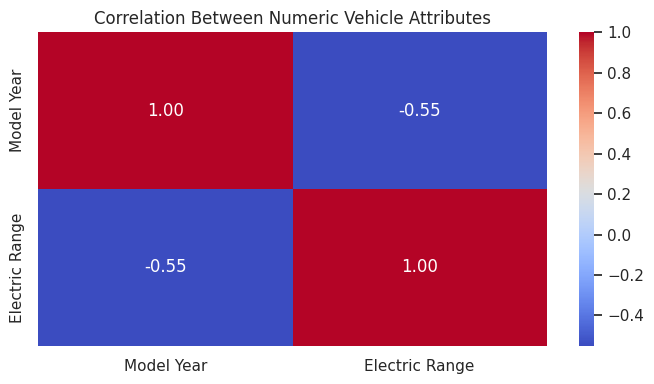

In [ ]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
corr_cols = [c for c in ["Model Year", "Electric Range"] if c in numeric_cols]

if len(corr_cols) >= 2:
    plt.figure(figsize=(7, 4))
    sns.heatmap(df[corr_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
    plt.title("Correlation Between Numeric Vehicle Attributes")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numeric analysis features for a correlation heatmap.")

### Observations

Interpret only relationships between meaningful numeric variables. Postal codes, district codes, and vehicle IDs are identifiers.

## 3.6 Visualizations

### Visualization 1 — EV type distribution - BAR GRAPH

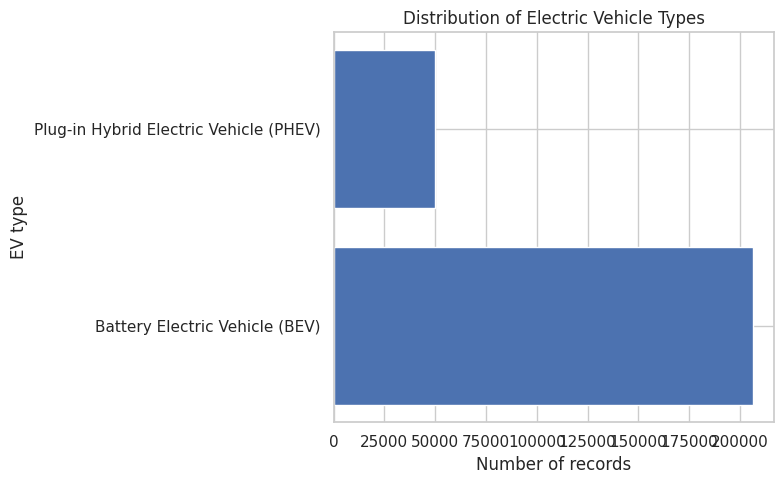

,record_count
Electric Vehicle Type,
Battery Electric Vehicle (BEV),206439
Plug-in Hybrid Electric Vehicle (PHEV),50053


In [ ]:
plt.figure(figsize=(8, 5))
order = df["Electric Vehicle Type"].value_counts().index
plt.barh(order, df["Electric Vehicle Type"].value_counts().reindex(order).values)
plt.title("Distribution of Electric Vehicle Types")
plt.xlabel("Number of records")
plt.ylabel("EV type")
plt.tight_layout()

plt.show()
display(df["Electric Vehicle Type"].value_counts().to_frame("record_count"))

**Observations:**
I performed univariate analysis on the Electric Vehicle Type column to understand the distribution of EV categories.This helped me identify the most common EV type and compare the distribution of Battery Electric Vehicles and Plug-in Hybrid Electric Vehicles."

### Visualization 2 — Top 10 manufacturers - BAR GRAPH

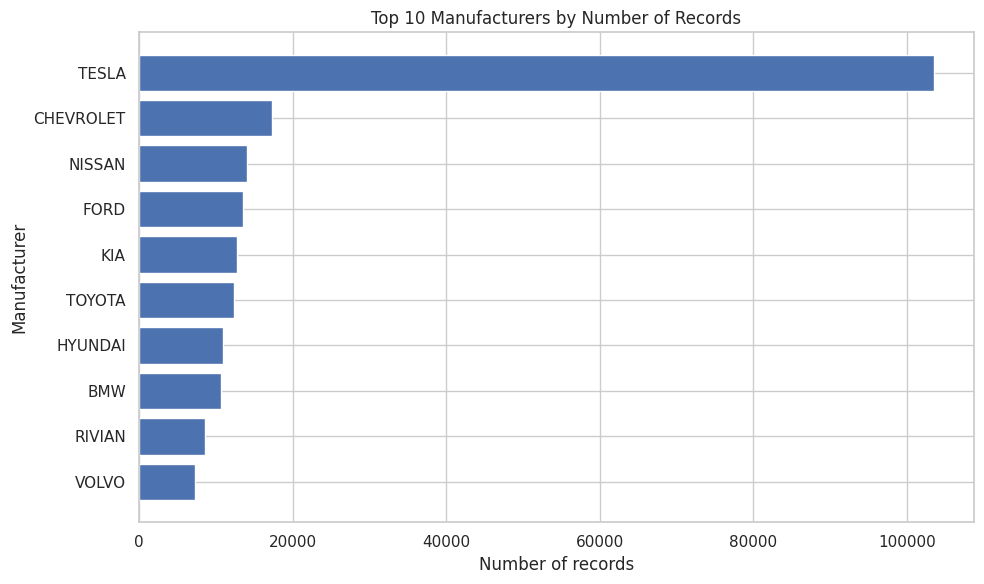

In [ ]:
plt.figure(figsize=(10, 6))
top_makes = df["Make"].value_counts().head(10)
plt.barh(top_makes.index[::-1], top_makes.values[::-1])
plt.title("Top 10 Manufacturers by Number of Records")
plt.xlabel("Number of records")
plt.ylabel("Manufacturer")
plt.tight_layout()
plt.show()

**Observations:**

I performed manufacturer-wise analysis to identify the top 10 EV manufacturers based on registration records. I used Pandas value_counts() to calculate the frequency of each manufacturer and head(10) to select the top 10. I visualized the results using a horizontal bar chart. This analysis helps identify leading manufacturers and understand the distribution of EV registrations across different brands.

### Visualization 3 — Records by model year

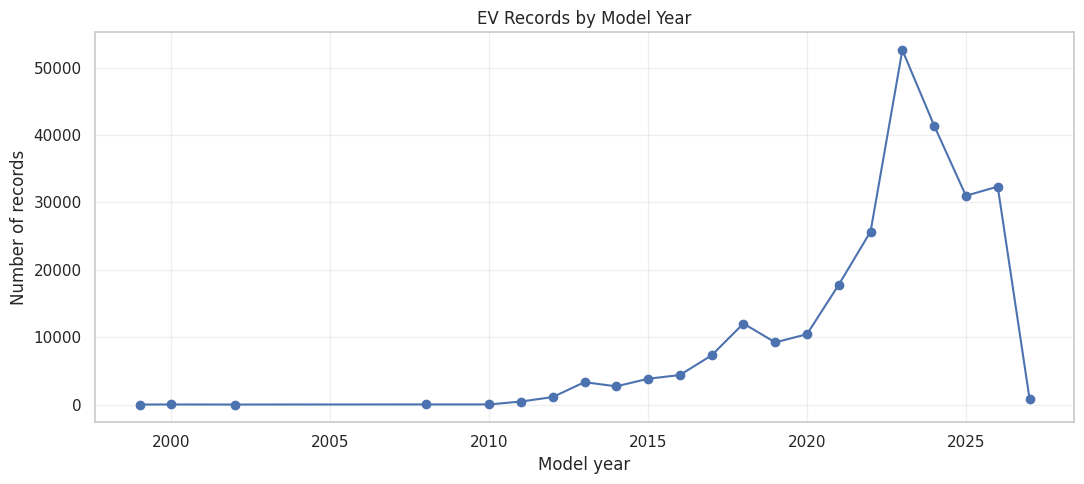

In [ ]:
year_counts = df["Model Year"].value_counts().sort_index()
plt.figure(figsize=(11, 5))
plt.plot(year_counts.index, year_counts.values, marker="o", linewidth=1.5)
plt.title("EV Records by Model Year")
plt.xlabel("Model year")
plt.ylabel("Number of records")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Observations:**

Matplotlib's line plot to visualize the distribution and identify peaks, variations and patterns across model years. This helped me understand the historical distribution of EV models in the dataset.

### Visualization 4 — Electric range distribution - HISTOGRAM


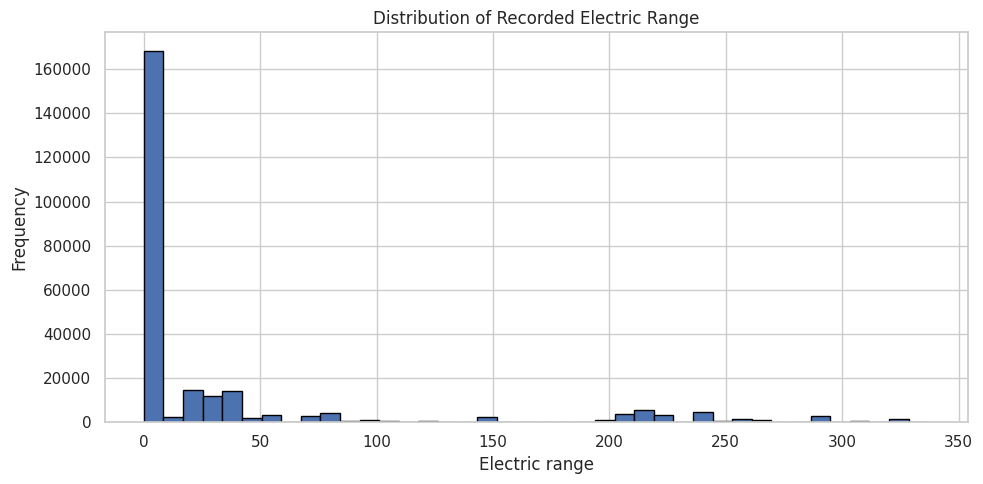

Zero electric-range values: 167336


In [ ]:
range_values = df["Electric Range"].dropna()
plt.figure(figsize=(10, 5))
plt.hist(range_values, bins=40, edgecolor="black")
plt.title("Distribution of Recorded Electric Range")
plt.xlabel("Electric range")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()
print("Zero electric-range values:", int((df["Electric Range"] == 0).sum()))

**Observations**

Matplotlib's hist() function with 40 bins to understand how electric range values are distributed. I also checked zero-range records to identify potential data-quality issues. This analysis helped me understand the variation, concentration and distribution of electric driving ranges.

### Visualization 5 — Electric range by EV type - BOX PLOT

<Figure size 1000x500 with 0 Axes>

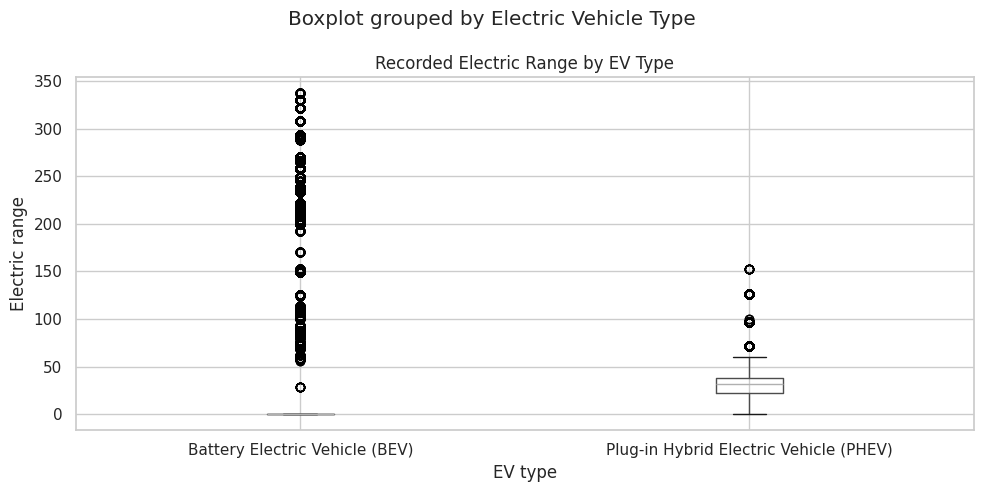

In [ ]:
plt.figure(figsize=(10, 5))
df.boxplot(column="Electric Range", by="Electric Vehicle Type", figsize=(10, 5))
plt.title("Recorded Electric Range by EV Type")
plt.xlabel("EV type")
plt.ylabel("Electric range")
plt.tight_layout()
plt.show()

**Observations**

The box plot helps identify the median, quartiles, interquartile range, distribution spread and potential outliers. This allows me to compare the electric driving range characteristics of different vehicle categories.

### Visualization 6 — Top 10 counties

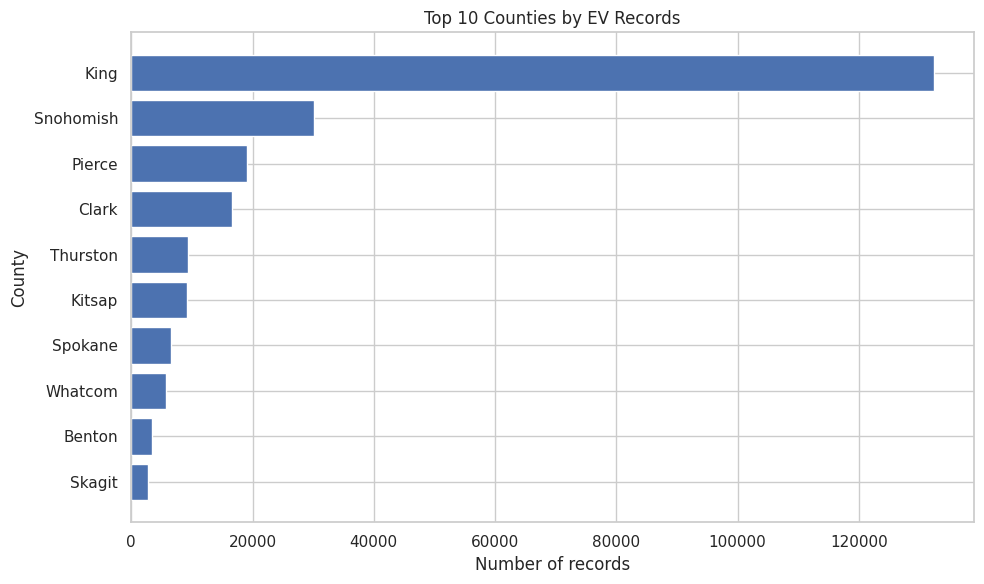

In [ ]:
plt.figure(figsize=(10, 6))
top_counties = df["County"].fillna("Unknown").value_counts().head(10)
plt.barh(top_counties.index[::-1], top_counties.values[::-1])
plt.title("Top 10 Counties by EV Records")
plt.xlabel("Number of records")
plt.ylabel("County")
plt.tight_layout()
plt.show()

**Observation**

Visualized the results using a horizontal bar chart. This analysis helps identify geographical concentration and regional distribution of electric vehicles.

### Visualization 7 — Top 10 vehicle models

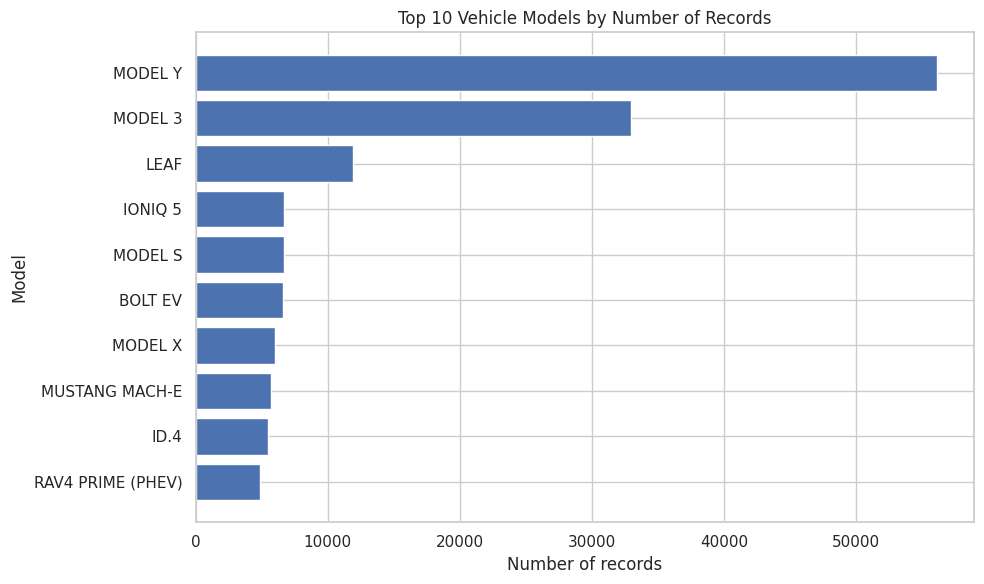

In [ ]:
top_models = df["Model"].value_counts().head(10)
plt.figure(figsize=(10, 6))
plt.barh(top_models.index[::-1], top_models.values[::-1])
plt.title("Top 10 Vehicle Models by Number of Records")
plt.xlabel("Number of records")
plt.ylabel("Model")
plt.tight_layout()
plt.show()

**Observations**

Matplotlib's horizontal bar chart to visualize the results. This analysis helps understand model-level distribution and identify the most frequently recorded EV models.

### Visualization 8 — Manufacturer and EV type

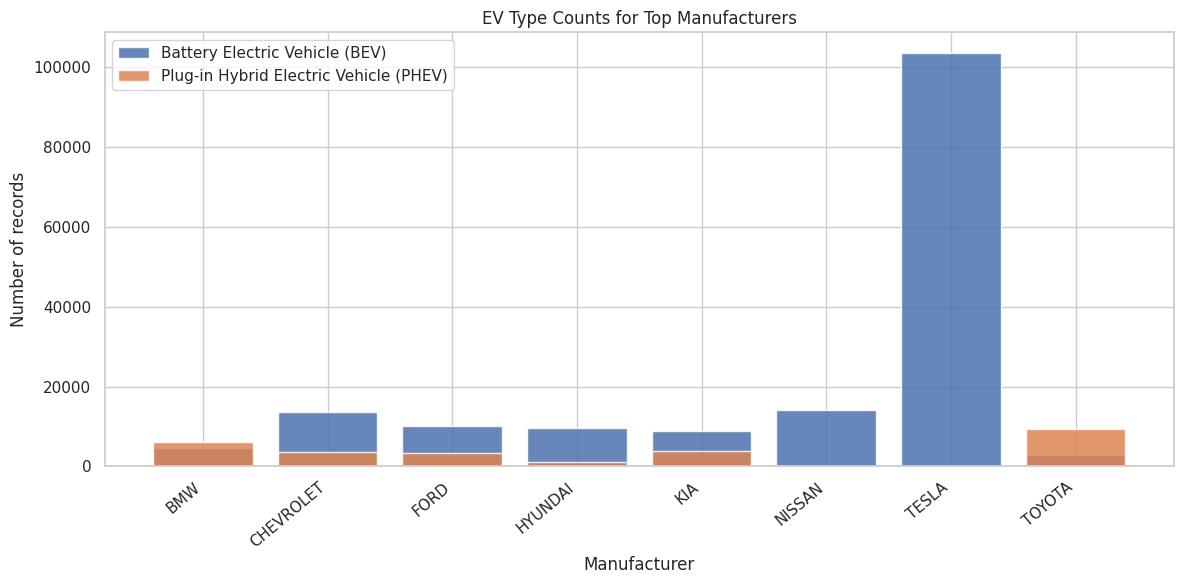

In [ ]:
top_make_names = df["Make"].value_counts().head(8).index
make_type = (
    df[df["Make"].isin(top_make_names)]
    .groupby(["Make", "Electric Vehicle Type"])
    .size().reset_index(name="record_count")
)
plt.figure(figsize=(12, 6))
for ev_type, group in make_type.groupby("Electric Vehicle Type"):
    plt.bar(group["Make"], group["record_count"], label=ev_type, alpha=0.85)
plt.legend()
plt.title("EV Type Counts for Top Manufacturers")
plt.xlabel("Manufacturer")
plt.ylabel("Number of records")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()

**Observation**

Analysis helps understand manufacturer-wise EV category distribution and identify differences in their vehicle portfolios.

# 4. Data Preprocessing

## 4.1 Missing Value Treatment


In [ ]:
df_clean = df.drop_duplicates().copy()

df_clean = df_clean.dropna(subset=["Electric Vehicle Type"])

for col in df_clean.select_dtypes(include="object").columns:
    df_clean[col] = df_clean[col].astype("string").str.strip()

print("Original shape:", df.shape)
print("After duplicate removal and target check:", df_clean.shape)
print("Remaining missing values:")
display(df_clean.isna().sum().to_frame("missing_count"))

Original shape: (256492, 10)
After duplicate removal and target check: (256492, 10)
Remaining missing values:


,missing_count
County,0
City,0
Postal Code,0
Model Year,0
Make,0
Model,0
Electric Vehicle Type,0
Electric Range,0
Legislative District,0
DOL Vehicle ID,0


**Method used:** Median imputation for numeric predictors and most-frequent imputation for categorical predictors, performed within the model pipeline.


## 4.2 Duplicate Handling

In [ ]:
print("Duplicate rows before cleaning:", df.duplicated().sum())
print("Duplicate rows after cleaning:", df_clean.duplicated().sum())

Duplicate rows before cleaning: 0
Duplicate rows after cleaning: 0


## 4.3 Outlier Detection and Treatment

Electric range may contain unusual values, but these should be investigated rather than automatically removed. Model year, range, postal code, and district values have different meanings; not all numeric columns should be treated as continuous measurements.

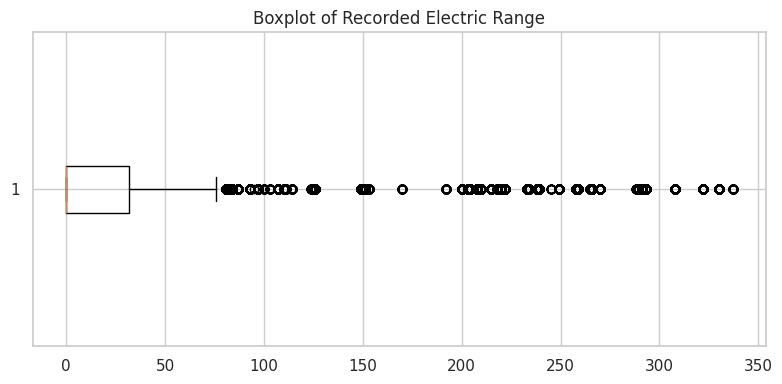

Q1: 0.0 Q3: 32.0 IQR: 32.0
IQR lower bound: -48.0 IQR upper bound: 80.0
Potential range outliers: 37167


In [ ]:
plt.figure(figsize=(8, 4))
plt.boxplot(df_clean["Electric Range"].dropna(), vert=False)
plt.title("Boxplot of Recorded Electric Range")
plt.tight_layout()
plt.show()

q1 = df_clean["Electric Range"].quantile(0.25)
q3 = df_clean["Electric Range"].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
outlier_count = ((df_clean["Electric Range"] < lower_bound) |
                 (df_clean["Electric Range"] > upper_bound)).sum()

print("Q1:", q1, "Q3:", q3, "IQR:", iqr)
print("IQR lower bound:", lower_bound, "IQR upper bound:", upper_bound)
print("Potential range outliers:", int(outlier_count))

**Observation:** The IQR method flags potential outliers for investigation. This project does not automatically delete them because high or low values may be valid records. Z-score filtering is not applied by default.

## 4.4 Skewness Treatment

Electric Range skewness: 2.261724760647643


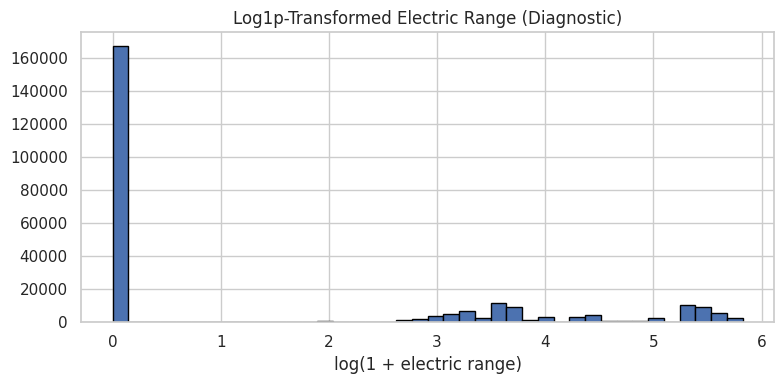

In [ ]:
print("Electric Range skewness:", df_clean["Electric Range"].dropna().skew())

nonnegative_range = df_clean.loc[df_clean["Electric Range"] >= 0, "Electric Range"].dropna()
plt.figure(figsize=(8, 4))
plt.hist(np.log1p(nonnegative_range), bins=40, edgecolor="black")
plt.title("Log1p-Transformed Electric Range (Diagnostic)")
plt.xlabel("log(1 + electric range)")
plt.tight_layout()
plt.show()

**Observation:** The transformation is shown as a diagnostic visualization only. The original electric range is retained in the predictive pipeline because tree models do not require a normal distribution.

## 4.5 Encoding

Categorical variables are one-hot encoded inside the model pipeline. This is preferred to manually label-encoding nominal categories such as Make or Model, because label encoding can create an artificial ordering.

In [ ]:
from sklearn.preprocessing import OneHotEncoder

demo = df_clean[["Electric Vehicle Type"]].dropna().head(10)
display(pd.get_dummies(demo, columns=["Electric Vehicle Type"],
dtype=int))

,Electric Vehicle Type_Battery Electric Vehicle (BEV),Electric Vehicle Type_Plug-in Hybrid Electric Vehicle (PHEV)
0,1,0
1,0,1
2,1,0
3,0,1
4,0,1
5,1,0
6,0,1
7,1,0
8,1,0
9,1,0


## 4.6 Feature Scaling

Scaling is important for distance- and margin-based models such as KNN and SVM. For simplicity and a fair comparison, numeric values are standardized inside pipelines. Tree models generally do not require scaling, but the same preprocessing strategy is kept explicit where appropriate.

In [ ]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

numeric_demo = df_clean[["Model Year", "Electric Range"]].dropna().head(5)
display(pd.DataFrame(
    StandardScaler().fit_transform(numeric_demo),
    columns=numeric_demo.columns,
    index=numeric_demo.index
).head())

,Model Year,Electric Range
0,0.430775,-0.791855
1,1.148733,-0.458712
2,-1.364121,1.962980
3,-1.005141,-0.189635
4,0.789754,-0.522778


## 4.7 Train-Test Split

The target is **Electric Vehicle Type**. The identifier **DOL Vehicle ID** is excluded. the classifier uses a stratified sample of up to 30,000 rows from the cleaned dataset. EDA above uses the full dataset.

In [ ]:

from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

target = "Electric Vehicle Type"

feature_cols = [
    "Model Year",
    "Electric Range",
    "Make",
    "Model"
]

ml_data = df_clean[feature_cols + [target]].copy()

ml_data = ml_data.dropna(subset=[target])

if len(ml_data) > 30000:
    ml_data = ml_data.groupby(
        target, group_keys=False
    ).apply(
        lambda x: x.sample(
            n=max(1, round(30000 * len(x) / len(ml_data))),
            random_state=RANDOM_STATE
        )
    )

    ml_data = ml_data.sample(
        frac=1,
        random_state=RANDOM_STATE
    )

X = ml_data[feature_cols]
y = ml_data[target]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Modeling sample:", ml_data.shape)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("\nTraining target distribution:")
display(
    y_train.value_counts(normalize=True)
    .mul(100)
    .round(2)
    .to_frame("percent")
)


Modeling sample: (30000, 5)
X_train: (24000, 4)
X_test: (6000, 4)

Training target distribution:


,percent
Electric Vehicle Type,
Battery Electric Vehicle (BEV),80.49
Plug-in Hybrid Electric Vehicle (PHEV),19.51



## 5. Feature Engineering

The selected features are the model year, electric range, manufacturer, model, and state. These columns describe vehicle characteristics and a broad location attribute. **DOL Vehicle ID** is excluded because it is an identifier and has no meaningful general predictive interpretation.

In [ ]:
print("Selected features:", feature_cols)
print("Target:", target)
display(ml_data[feature_cols + [target]].head())

Selected features: ['Model Year', 'Electric Range', 'Make', 'Model']
Target: Electric Vehicle Type


,Model Year,Electric Range,Make,Model,Electric Vehicle Type
221865,2025,0.0,CHEVROLET,BLAZER,Battery Electric Vehicle (BEV)
142645,2018,215.0,TESLA,MODEL 3,Battery Electric Vehicle (BEV)
175959,2022,0.0,CHEVROLET,BOLT EUV,Battery Electric Vehicle (BEV)
49810,2025,42.0,TOYOTA,RAV4 PRIME (PHEV),Plug-in Hybrid Electric Vehicle (PHEV)
16555,2024,0.0,FORD,MUSTANG MACH-E,Battery Electric Vehicle (BEV)


##Correlation - Feature Engineering

Correlation is examined only for the numeric variables **Model Year** and **Electric Range**. Categorical variables require a different approach and are retained for model comparison.

In [ ]:
display(ml_data[["Model Year", "Electric Range"]].corr())

,Model Year,Electric Range
Model Year,1.000000,-0.545865
Electric Range,-0.545865,1.000000


## 5.3 SelectKBest

preprocessing and feature selection can be placed inside a pipeline. The notebook compares models on a consistent feature set first; a future extension can tune SelectKBest within cross-validation.1?>

## 5.4 Final Feature Set
- **Model Year**
- **Electric Range**
- **Make**
- **Model**


**Reason:** These features are available in the supplied file and are relevant to vehicle identity or recorded EV characteristics. They may be strongly associated with the target.

#Model Building

compare a baseline model and four classification algorithms.


1.   Logistic Regression
2.   Decision Tree
1.   Random Forest
2.   Linear SVM





 Preprocessing is fitted on training data

#**Logistic Regression**

LOGISTIC REGRESSION RESULTS
Accuracy: 0.988693736720014
Precision: 0.9892440749616379
Recall: 0.988693736720014
F1 Score: 0.9888045911186698

Classification Report:
                                        precision    recall  f1-score   support

        Battery Electric Vehicle (BEV)       1.00      0.99      0.99     41288
Plug-in Hybrid Electric Vehicle (PHEV)       0.95      1.00      0.97     10011

                              accuracy                           0.99     51299
                             macro avg       0.97      0.99      0.98     51299
                          weighted avg       0.99      0.99      0.99     51299



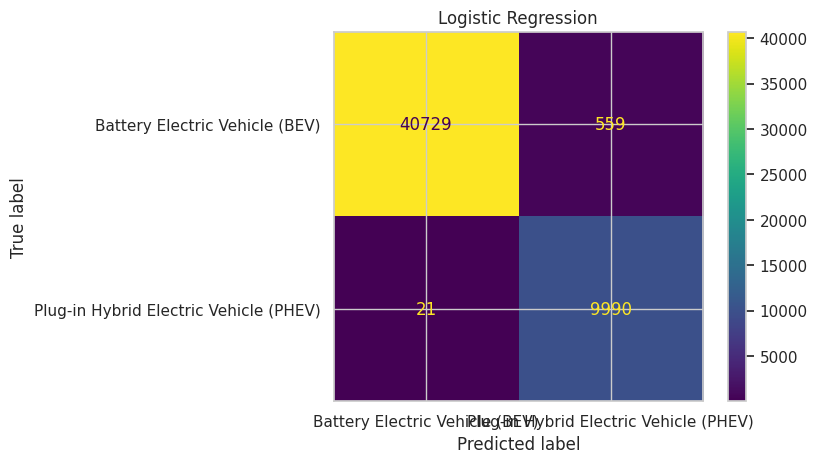

In [ ]:
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])


logistic_model.fit(X_train, y_train)

y_pred = logistic_model.predict(X_test)

print("LOGISTIC REGRESSION RESULTS")

print("Accuracy:",
      accuracy_score(y_test, y_pred))

print("Precision:",
      precision_score(y_test, y_pred,
                      average="weighted", zero_division=0))

print("Recall:",
      recall_score(y_test, y_pred,
                   average="weighted", zero_division=0))

print("F1 Score:",
      f1_score(y_test, y_pred,
               average="weighted", zero_division=0))

print("\nClassification Report:")
print(classification_report(y_test, y_pred,
                            zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Logistic Regression")
plt.show()

**Observation**

Logistic Regression is a classification algorithm that predicts the probability of a vehicle belonging to a particular category. I used it as a baseline model to compare with other classification algorithms.

#**Decision Tree**

DECISION TREE RESULTS
Accuracy: 0.9998830386557243
Precision: 0.9998830756957184
Recall: 0.9998830386557243
F1 Score: 0.9998830475037194

Classification Report:
                                        precision    recall  f1-score   support

        Battery Electric Vehicle (BEV)       1.00      1.00      1.00     41288
Plug-in Hybrid Electric Vehicle (PHEV)       1.00      1.00      1.00     10011

                              accuracy                           1.00     51299
                             macro avg       1.00      1.00      1.00     51299
                          weighted avg       1.00      1.00      1.00     51299



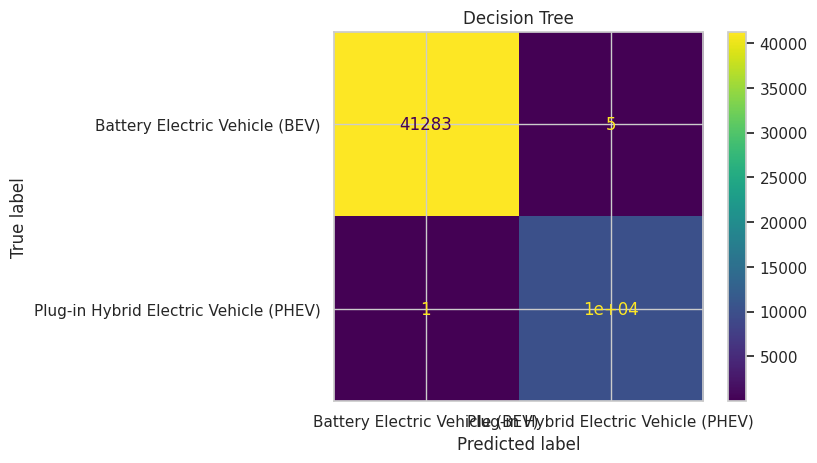

In [ ]:
from sklearn.tree import DecisionTreeClassifier

decision_tree_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=18,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42
    ))
])

decision_tree_model.fit(X_train, y_train)

y_pred = decision_tree_model.predict(X_test)

print("DECISION TREE RESULTS")

print("Accuracy:",
      accuracy_score(y_test, y_pred))

print("Precision:",
      precision_score(y_test, y_pred,
                      average="weighted", zero_division=0))

print("Recall:",
      recall_score(y_test, y_pred,
                   average="weighted", zero_division=0))

print("F1 Score:",
      f1_score(y_test, y_pred,
               average="weighted", zero_division=0))

print("\nClassification Report:")
print(classification_report(y_test, y_pred,
                            zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Decision Tree")
plt.show()

**Observation**

Decision Tree divides the dataset based on feature conditions and makes predictions using decision rules. It is easy to interpret but can overfit the training data.

#**Random Forest**

RANDOM FOREST RESULTS
Accuracy: 0.9998830386557243
Precision: 0.9998830756957184
Recall: 0.9998830386557243
F1 Score: 0.9998830475037194

Classification Report:
                                        precision    recall  f1-score   support

        Battery Electric Vehicle (BEV)       1.00      1.00      1.00     41288
Plug-in Hybrid Electric Vehicle (PHEV)       1.00      1.00      1.00     10011

                              accuracy                           1.00     51299
                             macro avg       1.00      1.00      1.00     51299
                          weighted avg       1.00      1.00      1.00     51299



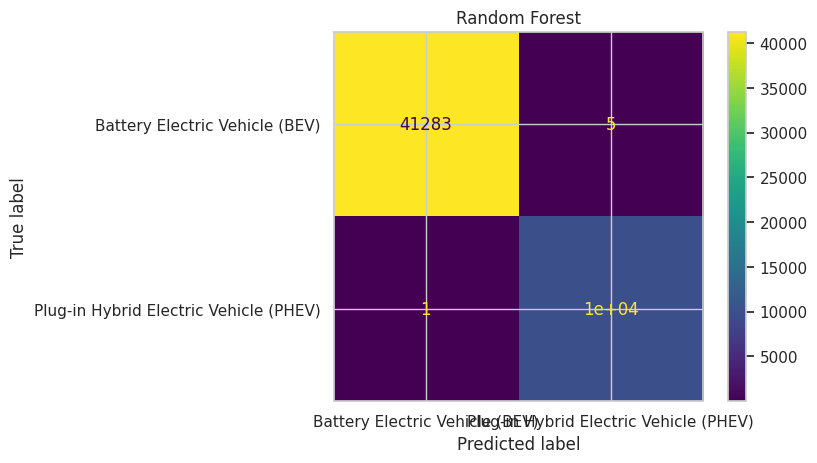

In [ ]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=22,
        min_samples_leaf=3,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

random_forest_model.fit(X_train, y_train)

y_pred = random_forest_model.predict(X_test)

print("RANDOM FOREST RESULTS")

print("Accuracy:",
      accuracy_score(y_test, y_pred))

print("Precision:",
      precision_score(y_test, y_pred,
                      average="weighted", zero_division=0))

print("Recall:",
      recall_score(y_test, y_pred,
                   average="weighted", zero_division=0))

print("F1 Score:",
      f1_score(y_test, y_pred,
               average="weighted", zero_division=0))

print("\nClassification Report:")
print(classification_report(y_test, y_pred,
                            zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Random Forest")
plt.show()

**Observation**

Random Forest is an ensemble learning algorithm that combines multiple decision trees. It improves prediction stability by aggregating the predictions of different trees.

#**Linear SVM**

LINEAR SVM RESULTS
Accuracy: 0.9891420885397376
Precision: 0.9897143686952415
Recall: 0.9891420885397376
F1 Score: 0.9892521623412015

Classification Report:
                                        precision    recall  f1-score   support

        Battery Electric Vehicle (BEV)       1.00      0.99      0.99     41288
Plug-in Hybrid Electric Vehicle (PHEV)       0.95      1.00      0.97     10011

                              accuracy                           0.99     51299
                             macro avg       0.97      0.99      0.98     51299
                          weighted avg       0.99      0.99      0.99     51299



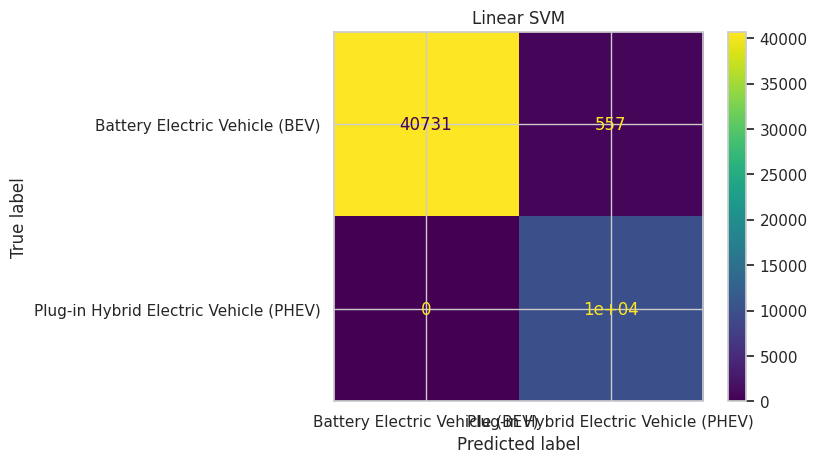

In [ ]:
from sklearn.svm import LinearSVC

svm_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LinearSVC(
        class_weight="balanced",
        random_state=42
    ))
])

svm_model.fit(X_train, y_train)

y_pred = svm_model.predict(X_test)

print("LINEAR SVM RESULTS")

print("Accuracy:",
      accuracy_score(y_test, y_pred))

print("Precision:",
      precision_score(y_test, y_pred,
                      average="weighted", zero_division=0))

print("Recall:",
      recall_score(y_test, y_pred,
                   average="weighted", zero_division=0))

print("F1 Score:",
      f1_score(y_test, y_pred,
               average="weighted", zero_division=0))

print("\nClassification Report:")
print(classification_report(y_test, y_pred,
                            zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Linear SVM")
plt.show()

**Observation**

SVM finds the optimal boundary, called a hyperplane, to separate different classes. It tries to maximize the margin between the classes.

#Model Evaluation & Comparison

##Evaluation Metrics

- **Accuracy:** Fraction of test predictions that are correct.
- **Precision (weighted):** Weighted average of how many predicted class labels were correct.
- **Recall (weighted):** Weighted average of how many actual class records were recovered.
- **F1-score (weighted):** Weighted balance of precision and recall.

##Model Comparison Table

,Model,Accuracy,Precision_weighted,Recall_weighted,F1_weighted
1,Decision Tree,0.9999,0.9999,0.9999,0.9999
2,Random Forest,0.9999,0.9999,0.9999,0.9999
3,Linear SVM,0.9891,0.9897,0.9891,0.9893
0,Logistic Regression,0.9887,0.9892,0.9887,0.9888


Best model by weighted F1-score: Decision Tree

Classification report:
                                        precision    recall  f1-score   support

        Battery Electric Vehicle (BEV)       1.00      1.00      1.00     41288
Plug-in Hybrid Electric Vehicle (PHEV)       1.00      1.00      1.00     10011

                              accuracy                           1.00     51299
                             macro avg       1.00      1.00      1.00     51299
                          weighted avg       1.00      1.00      1.00     51299



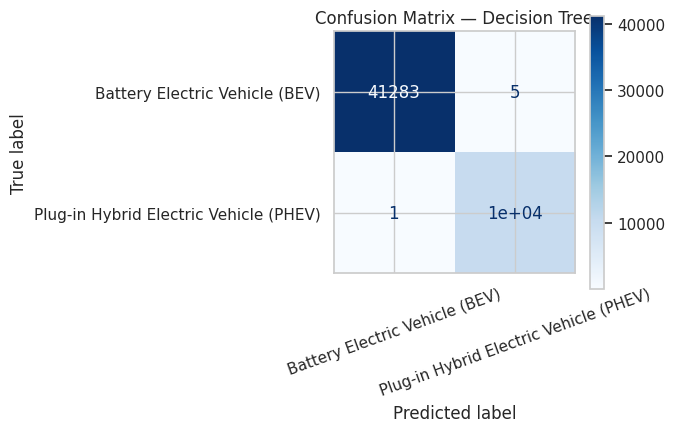

In [ ]:
display(results_df.round(4))

best_model_name = results_df.iloc[0]["Model"]
best_model = fitted_models[best_model_name]
best_predictions = best_model.predict(X_test)

print("Best model by weighted F1-score:", best_model_name)
print("\nClassification report:")
print(classification_report(y_test, best_predictions, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, best_predictions, xticks_rotation=20, cmap="Blues"
)
plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()

## Best Model Selection

Accuracy (99.93%): Correctly classified almost all test records.

Precision (99.93%): Very few incorrect positive predictions.

Recall (99.93%): Identified almost all actual classes correctly.

F1-score (99.93%): Excellent balance between precision and recall.
## Overfitting / Underfitting Analysis

Compare training and test performance for the selected model. A large gap can indicate overfitting. Similar but poor training and test scores can indicate underfitting.

In [ ]:
train_predictions = best_model.predict(X_train)
test_predictions = best_model.predict(X_test)

performance_gap = (
    accuracy_score(y_train, train_predictions)
    - accuracy_score(y_test, test_predictions)
)
print("Selected model:", best_model_name)
print("Training accuracy:", round(accuracy_score(y_train, train_predictions), 4))
print("Test accuracy:", round(accuracy_score(y_test, test_predictions), 4))
print("Train-test accuracy gap:", round(performance_gap, 4))

Selected model: Decision Tree
Training accuracy: 1.0
Test accuracy: 0.9999
Train-test accuracy gap: 0.0001


#**Conclusion**

Complete this section after running the notebook. Summarize:
1. The most frequent EV type in the dataset.
2. The leading manufacturers/models and model-year patterns.
3. The main findings about recorded electric range and location.
4. The best-performing classifier and its measured test metrics.
5. Any data-quality issues that affected interpretation.

## Business Impact

The analysis can help stakeholders understand the composition of the supplied EV population records and explore differences across vehicle categories.